# Lecture 6 notebook: Trend following, the map and the machinery

Companion to Lecture 6 of *Systematic Trading Notes*; sections are numbered as in the lecture. Lecture 5 asked what a
market makes available to a trend rule; this notebook measures how design decides what a system captures.

Data: the 16 ETFs of Lecture 5, daily adjusted closes, highs and lows. Every rule decides its position at the close
of day $t$ and earns the return of day $t+1$. Positions are sized to a 10% annual volatility per asset unless a
section says otherwise, and the portfolio is the equal-weighted average of the assets available on each day.
Results on one history are preliminary.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "06-trend-following-map-and-machinery" / "figures"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
D = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")
C, H, L = (D[f][TICKERS] for f in ("close", "high", "low"))
r = np.log(C).diff()                                     # daily log returns
vol = r.ewm(span=60, min_periods=60).std()               # daily volatility, known at each close
TARGET = 0.10 / np.sqrt(252)
START = "2000-01-01"

## 2. The map

### 2.5 Every linear rule is a set of weights on past returns (toy, by hand)

Price minus its $N$-day simple average, written in past returns: with $\Delta p$ the daily price changes,
$p_t - \text{SMA}_N = \sum_{k=0}^{N-2} \frac{N-1-k}{N}\,\Delta p_{t-k}$. For $N=4$ the weights on the last three changes are
3/4, 2/4 and 1/4: recent changes count most. The 12-month return sign weights the last 252 returns equally.

In [2]:
p = pd.Series([100.0, 101.0, 103.0, 102.0, 105.0])
N = 4
direct = p.iloc[-1] - p.iloc[-N:].mean()
dp = p.diff().iloc[-(N - 1):][::-1].to_numpy()          # most recent change first
w = np.array([(N - 1 - k) / N for k in range(N - 1)])
print("prices", p.tolist())
print(f"price minus SMA(4) directly: {direct:.4f}")
print("weights on the last 3 changes (most recent first):", w.tolist(), " changes:", dp.tolist())
print(f"weighted sum of changes: {w @ dp:.4f}")
assert np.isclose(direct, w @ dp)

prices [100.0, 101.0, 103.0, 102.0, 105.0]
price minus SMA(4) directly: 2.2500
weights on the last 3 changes (most recent first): [0.75, 0.5, 0.25]  changes: [3.0, -1.0, 2.0]
weighted sum of changes: 2.2500


### 2.6 Five representative rules and how much they overlap (Tables 2.1 and 2.2)

| Rule | Family | Signal |
|---|---|---|
| TSMOM-12 | Linear | Sign of the 252-day return |
| SMA-200 | Linear | Sign of price minus its 200-day average |
| EWMAC 16/64 | Linear, continuous | (EMA16 − EMA64) / price volatility, scaled to an average absolute forecast of 1, capped at 2 |
| Donchian 55/20 | Price extremes | Long above the 55-day high, out below the 20-day low; short symmetrically |
| Chandelier 55 | Price extremes, stop | Enter on the 55-day breakout; exit when price falls 3 ATR(20) below its highest close since entry (short symmetrically) |

In [3]:
def ewmac(c, fast=16, slow=64):
    raw = c.ewm(span=fast).mean() - c.ewm(span=slow).mean()
    f = raw / (c * vol)                                   # in units of daily price volatility
    f = f / f.abs().loc[START:].median().median()         # average absolute forecast about 1 (full-sample scalar; a simplification)
    return f.clip(-2, 2)


def donchian(c, entry=55, exit_=20):
    hi_e, lo_e = c.rolling(entry).max().shift(1), c.rolling(entry).min().shift(1)
    hi_x, lo_x = c.rolling(exit_).max().shift(1), c.rolling(exit_).min().shift(1)
    out = pd.DataFrame(0.0, index=c.index, columns=c.columns)
    for t_ in c.columns:
        pos, ps = 0.0, []
        for px, he, le, hx, lx in zip(c[t_], hi_e[t_], lo_e[t_], hi_x[t_], lo_x[t_]):
            if np.isnan(px) or np.isnan(he):
                pos = 0.0
            elif pos == 0 and px > he:
                pos = 1.0
            elif pos == 0 and px < le:
                pos = -1.0
            elif pos == 1 and px < lx:
                pos = -1.0 if px < le else 0.0
            elif pos == -1 and px > hx:
                pos = 1.0 if px > he else 0.0
            ps.append(pos)
        out[t_] = ps
    return out


def chandelier(c, h, l, entry=55, k=3.0, n_atr=20):
    tr = pd.concat({t_: pd.concat([h[t_] - l[t_], (h[t_] - c[t_].shift()).abs(), (l[t_] - c[t_].shift()).abs()], axis=1).max(axis=1) for t_ in c.columns}, axis=1)
    atr = tr.rolling(n_atr).mean()
    hi_e, lo_e = c.rolling(entry).max().shift(1), c.rolling(entry).min().shift(1)
    out = pd.DataFrame(0.0, index=c.index, columns=c.columns)
    for t_ in c.columns:
        pos, ext, ps = 0.0, np.nan, []
        for px, he, le, a in zip(c[t_], hi_e[t_], lo_e[t_], atr[t_]):
            if np.isnan(px) or np.isnan(he) or np.isnan(a):
                pos = 0.0
            elif pos == 0:
                if px > he:
                    pos, ext = 1.0, px
                elif px < le:
                    pos, ext = -1.0, px
            elif pos == 1:
                ext = max(ext, px)
                if px < ext - k * a:
                    pos = 0.0
            elif pos == -1:
                ext = min(ext, px)
                if px > ext + k * a:
                    pos = 0.0
            ps.append(pos)
        out[t_] = ps
    return out


signals = {
    "TSMOM-12": np.sign(np.log(C).diff(252)),
    "SMA-200": np.sign(C - C.rolling(200).mean()),
    "EWMAC 16/64": ewmac(C),
    "Donchian 55/20": donchian(C),
    "Chandelier 55": chandelier(C, H, L),
}


def run(sig, scale=True):
    pos = sig * (TARGET / vol if scale else 1.0)
    rets = (pos.shift(1) * r)                             # decided at the close, earned the next day
    port = rets.loc[START:].mean(axis=1)
    turnover = pos.diff().abs().loc[START:].mean(axis=1)  # traded notional per day, as a share of capital per asset
    return port, pos, turnover


res = {k: run(s) for k, s in signals.items()}
daily = pd.DataFrame({k: v[0] for k, v in res.items()}).dropna()
print("Table 2.1  correlation of daily portfolio returns")
display(daily.corr().round(2))
agree = {}
for a in signals:
    agree[a] = {b: (np.sign(signals[a]).loc[START:] == np.sign(signals[b]).loc[START:]).stack().mean() for b in signals}
print("Table 2.2  share of asset-days on which the two rules hold the same direction (long, flat or short)")
display(pd.DataFrame(agree).round(2))

Table 2.1  correlation of daily portfolio returns


,TSMOM-12,SMA-200,EWMAC 16/64,Donchian 55/20,Chandelier 55
TSMOM-12,1.00,0.74,0.61,0.41,0.40
SMA-200,0.74,1.00,0.86,0.71,0.69
EWMAC 16/64,0.61,0.86,1.00,0.91,0.89
Donchian 55/20,0.41,0.71,0.91,1.00,0.97
Chandelier 55,0.40,0.69,0.89,0.97,1.00


Table 2.2  share of asset-days on which the two rules hold the same direction (long, flat or short)


,TSMOM-12,SMA-200,EWMAC 16/64,Donchian 55/20,Chandelier 55
TSMOM-12,0.88,0.72,0.64,0.41,0.38
SMA-200,0.72,0.89,0.76,0.49,0.46
EWMAC 16/64,0.64,0.76,0.90,0.56,0.52
Donchian 55/20,0.41,0.49,0.56,1.00,0.91
Chandelier 55,0.38,0.46,0.52,0.91,1.00


## 3. Design choices and what they capture

### 3.2 Direction and speed decide crisis behaviour (Table 3.1)

Monthly time-series momentum, sized to 10% volatility per asset, 2000–2026: long/short, long/flat and short/flat,
with 3-month and 12-month lookbacks. *Smile* is the coefficient on SPY's squared monthly return in a regression
of the portfolio's monthly return on SPY's return and its square (Moskowitz, Ooi and Pedersen, 2012, Table 3).

In [4]:
Rm = np.log(C).resample("ME").last().diff().loc[: C.index[-1] - pd.offsets.MonthEnd(1)]
volm = Rm.rolling(12).std().shift(1)
spy = Rm["SPY"]


def monthly_tsmom(lookback, mode):
    s = np.sign(Rm.rolling(lookback).sum()).shift(1)
    if mode == "long/flat":
        s = s.clip(lower=0)
    elif mode == "short/flat":
        s = s.clip(upper=0)
    return (s * (0.10 / np.sqrt(12)) / volm * Rm).mean(axis=1).loc["2000":]


rows = {}
for lb in (3, 12):
    for mode in ("long/short", "long/flat", "short/flat"):
        pm = monthly_tsmom(lb, mode)
        d = pd.concat([pm, spy], axis=1, keys=["p", "m"]).dropna()
        X = np.column_stack([np.ones(len(d)), d.m, d.m ** 2])
        b = np.linalg.lstsq(X, d.p, rcond=None)[0]
        e = d.p - X @ b
        se = np.sqrt(np.diag(e @ e / (len(d) - 3) * np.linalg.inv(X.T @ X)))
        q = pd.qcut(d.m, 5, labels=False)
        rows[f"{lb}-month {mode}"] = {"return % a year": 1200 * d.p.mean(), "beta to SPY": b[1], "smile": b[2], "t(smile)": b[2] / se[2],
                                      "SPY worst 20% of months": 1200 * d.p[q == 0].mean(), "SPY best 20% of months": 1200 * d.p[q == 4].mean(),
                                      "2008 %": 100 * d.p.loc["2008"].sum(), "March 2020 %": 100 * d.p.loc["2020-03"].sum(), "2022 %": 100 * d.p.loc["2022"].sum()}
design = pd.DataFrame(rows).T
display(design.round(2))

,return % a year,beta to SPY,smile,t(smile),SPY worst 20% of months,SPY best 20% of months,2008 %,March 2020 %,2022 %
3-month long/short,2.25,-0.08,0.69,2.34,3.39,-3.76,10.05,8.02,4.97
3-month long/flat,3.18,0.17,0.05,0.27,-13.31,13.26,-3.05,-0.44,-3.16
3-month short/flat,-0.94,-0.25,0.64,3.90,16.70,-17.02,13.10,8.46,8.13
12-month long/short,4.45,0.03,0.61,2.04,-2.25,4.69,8.68,-0.91,2.03
12-month long/flat,4.28,0.22,0.01,0.06,-16.13,17.48,-3.74,-4.91,-4.63
12-month short/flat,0.17,-0.19,0.60,4.08,13.88,-12.79,12.42,4.00,6.66


## 5. From forecast to position

### 5.2 Volatility scaling (Table 5.1)

The same monthly 12-month long/short rule, with equal notional in every asset against positions sized to 10%
volatility per asset (the volatility-scaled version rescaled to the same overall volatility for comparison).

In [5]:
def stats(x, per_year=12):
    x = x.dropna()
    cum = x.cumsum()
    return {"return % a year": 100 * per_year * x.mean(), "volatility % a year": 100 * np.sqrt(per_year) * x.std(),
            "Sharpe ratio": np.sqrt(per_year) * x.mean() / x.std(), "skewness": x.skew(),
            "worst month %": 100 * x.min(), "max drawdown %": 100 * (cum - cum.cummax()).min()}


s12 = np.sign(Rm.rolling(12).sum()).shift(1)
eq = (s12 * Rm).mean(axis=1).loc["2000":]
vs = (s12 * (0.10 / np.sqrt(12)) / volm * Rm).mean(axis=1).loc["2000":]
vs = vs * eq.std() / vs.std()
display(pd.DataFrame({"equal notional": stats(eq), "volatility-scaled": stats(vs)}).T.round(2))

,return % a year,volatility % a year,Sharpe ratio,skewness,worst month %,max drawdown %
equal notional,5.82,11.75,0.50,0.12,-11.24,-29.38
volatility-scaled,8.86,11.75,0.75,-0.03,-9.03,-26.24


## 6. Costs and turnover (Table 6.1)

Annual turnover per asset (traded notional as a multiple of capital) and the Sharpe ratio after costs of 0, 5 and
20 basis points per unit traded. Daily rules, 2000–2026.

In [6]:
rows = {}
for k, (port, pos, to) in res.items():
    ann_to = 252 * to.mean()
    out = {"turnover per year": ann_to}
    for c_bp in (0, 5, 20):
        net = port - to * c_bp / 1e4
        out[f"Sharpe at {c_bp} bp"] = np.sqrt(252) * net.mean() / net.std()
    rows[k] = out
display(pd.DataFrame(rows).T.round(2))

,turnover per year,Sharpe at 0 bp,Sharpe at 5 bp,Sharpe at 20 bp
TSMOM-12,9.88,0.56,0.47,0.20
SMA-200,13.80,0.42,0.29,-0.09
EWMAC 16/64,11.96,0.32,0.24,0.01
Donchian 55/20,7.95,0.19,0.10,-0.16
Chandelier 55,8.19,0.18,0.08,-0.20


## 7. The payoff profile (Table 7.1)

Monthly returns of each rule's portfolio, 2000–2026.

In [7]:
rows = {}
for k, (port, pos, to) in res.items():
    m = port.resample("ME").sum()
    m = m[m != 0]
    wins, losses = m[m > 0], m[m < 0]
    rows[k] = {**stats(m), "share of months positive": (m > 0).mean(), "average win / average loss": wins.mean() / -losses.mean()}
profile = pd.DataFrame(rows).T
display(profile.round(2))

,return % a year,volatility % a year,Sharpe ratio,skewness,worst month %,max drawdown %,share of months positive,average win / average loss
TSMOM-12,3.08,5.04,0.61,-0.05,-3.89,-12.15,0.57,1.15
SMA-200,2.25,4.86,0.46,0.09,-4.18,-9.66,0.56,1.12
EWMAC 16/64,2.45,6.65,0.37,0.74,-5.00,-16.02,0.52,1.23
Donchian 55/20,0.85,3.99,0.21,0.86,-2.59,-10.89,0.50,1.19
Chandelier 55,0.76,3.74,0.20,0.99,-2.76,-11.52,0.51,1.13


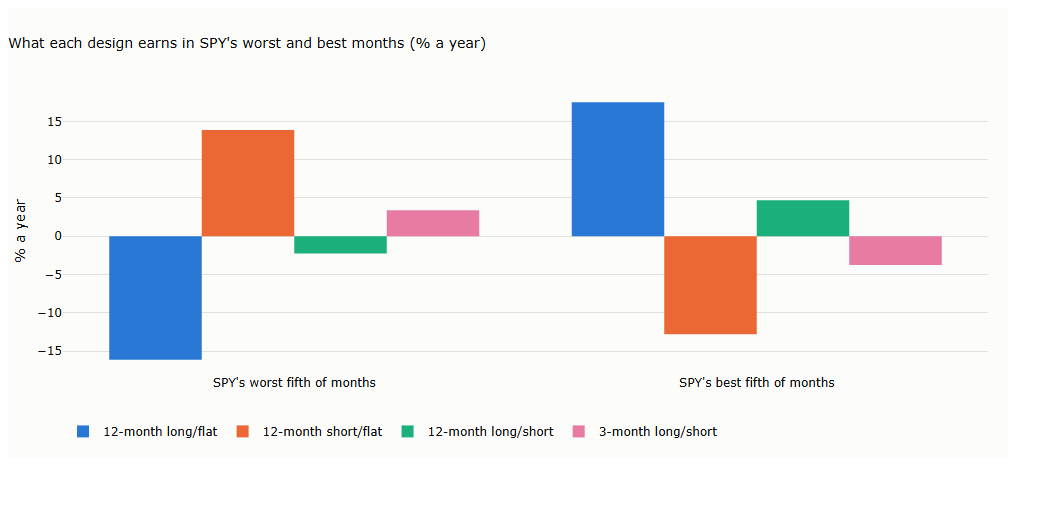

In [8]:
fig = go.Figure()
for j, (name, row) in enumerate(design.iterrows()):
    pass
x = ["SPY worst 20% of months", "SPY best 20% of months"]
for j, name in enumerate(["12-month long/flat", "12-month short/flat", "12-month long/short", "3-month long/short"]):
    fig.add_bar(name=name, x=["SPY's worst fifth of months", "SPY's best fifth of months"], y=design.loc[name, x].values, marker_color=SERIES[j])
fig.update_layout(barmode="group", title="What each design earns in SPY's worst and best months (% a year)", yaxis_title="% a year",
                  height=450, width=1000, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "06_01_direction_speed", FIG)
fig

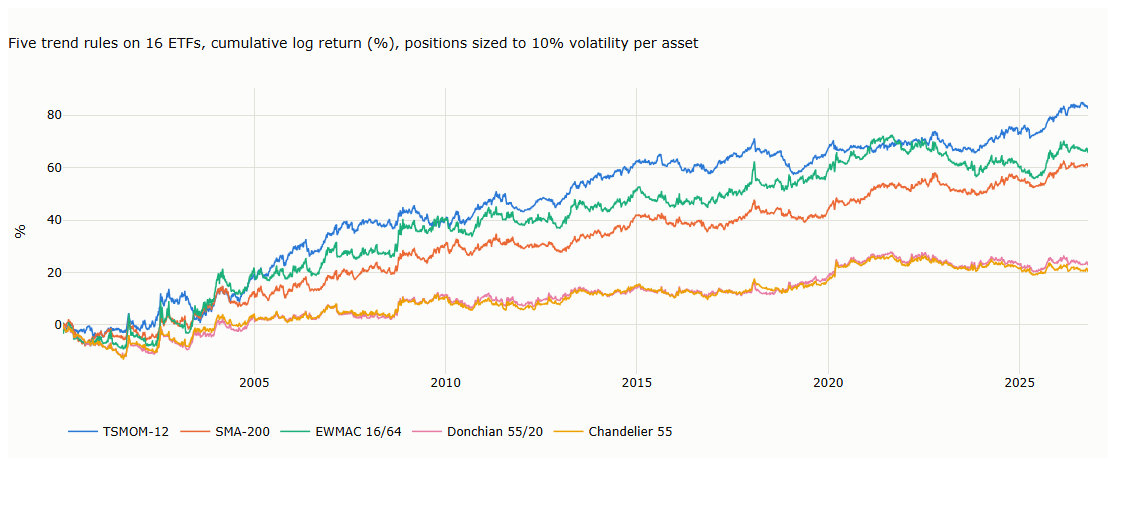

In [9]:
cum = daily.cumsum()
fig = go.Figure()
for j, k in enumerate(cum.columns):
    fig.add_scatter(x=cum.index, y=100 * cum[k], name=k, mode="lines", line=dict(width=1.5, color=SERIES[j % len(SERIES)]))
fig.update_layout(title="Five trend rules on 16 ETFs, cumulative log return (%), positions sized to 10% volatility per asset",
                  yaxis_title="%", height=450, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "06_02_five_rules", FIG)
fig